In [ ]:
!nvidia-smi

Sat Oct 10 04:59:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 8.2 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO
print("Ultralytics installed successfully")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics installed successfully


In [ ]:
!pip install -q roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 86.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 4.4 MB/s eta 0:00:00


In [ ]:
from roboflow import Roboflow

In [ ]:
import requests

API_KEY = "********************************"

response = requests.get(
    "https://api.roboflow.com/",
    params={"api_key": API_KEY}
)

print("Status:", response.status_code)
print(response.text)

Status: 200
{"welcome":"Welcome to the Roboflow API.","instructions":"You are successfully authenticated.","docs":"https://docs.roboflow.com","workspace":"vaishnavis-workspace-vuurp","workspaceId":"v6EYF3taeQWqXwBnt7f0akM08m13"}


In [ ]:
import requests

API_KEY = "********************************"

url = "https://api.roboflow.com/workspace/vaishnavis-workspace-vuurp"

response = requests.get(
    url,
    params={"api_key": API_KEY}
)

print("Status:", response.status_code)
print(response.text[:10000])

Status: 404
{"error":{"message":"Unsupported request. `GET /workspace/vaishnavis-workspace-vuurp` does not exist or cannot be loaded due to missing permissions.","type":"GraphMethodException","hint":"You can see your active workspace by issuing a GET request to `/` with your `api_key`."}}


In [ ]:
import requests

API_KEY = "********************************"

url = "https://api.roboflow.com/vaishnavis-workspace-vuurp/fire-smoke-videos/3/yolov8"

response = requests.get(
    url,
    params={"api_key": API_KEY}
)

print("Status:", response.status_code)
print(response.text[:2000])

Status: 200
{"workspace":{"name":"Vaishnavis Workspace","url":"vaishnavis-workspace-vuurp","members":2},"project":{"id":"vaishnavis-workspace-vuurp/fire-smoke-videos","type":"object-detection","name":"fire-smoke-videos","created":1787135244.369,"updated":1788093950.158,"images":1055,"unannotated":1056,"annotation":"fire-smoke-videos","versions":3,"public":true,"license":"MIT","splits":{"test":105,"train":844,"valid":106},"colors":{"Fire":"#C7FC00","Smoke":"#8622FF"},"classes":{"Fire":816,"Smoke":1165},"icon":{"original":"https://source.roboflow.com/v6EYF3taeQWqXwBnt7f0akM08m13/x1x3fon4HAFjlWtPElgl/original.jpg","thumb":"https://source.roboflow.com/v6EYF3taeQWqXwBnt7f0akM08m13/x1x3fon4HAFjlWtPElgl/thumb.jpg","annotation":null}},"version":{"id":"vaishnavis-workspace-vuurp/fire-smoke-videos/3","name":"2026-08-30 6:15pm","created":1788093950.158,"images":1899,"splits":{"valid":106,"test":105,"train":1688},"preprocessing":{"auto-orient":{"enabled":true},"resize":{"enabled":true,"width":640,

In [ ]:
import requests

API_KEY = "********************************"

url = "https://api.roboflow.com/vaishnavis-workspace-vuurp/fire-smoke-videos/3/yolov8"

response = requests.get(
    url,
    params={"api_key": API_KEY}
)

data = response.json()

download_url = data["export"]["link"]

print(download_url)

https://app.roboflow.com/ds/0mnhe7jUYH?key=RvMEOyzDbG


In [ ]:
r = requests.get(download_url)

print("Status:", r.status_code)
print("Size:", len(r.content) / (1024 * 1024), "MB")

Status: 200
Size: 100.05413913726807 MB


In [ ]:
with open("/content/fire_smoke_v3.zip", "wb") as f:
    f.write(r.content)

print("Dataset downloaded successfully")

Dataset downloaded successfully


In [ ]:
import zipfile

zip_path = "/content/fire_smoke_v3.zip"
extract_path = "/content/fire_smoke_v3"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully")

Dataset extracted successfully


In [ ]:
!find /content/fire_smoke_v3 -maxdepth 3 -type d

/content/fire_smoke_v3
/content/fire_smoke_v3/test
/content/fire_smoke_v3/test/labels
/content/fire_smoke_v3/test/images
/content/fire_smoke_v3/train
/content/fire_smoke_v3/train/labels
/content/fire_smoke_v3/train/images
/content/fire_smoke_v3/valid
/content/fire_smoke_v3/valid/labels
/content/fire_smoke_v3/valid/images


In [ ]:
!cat /content/fire_smoke_v3/data.yaml

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 2
names: ['Fire', 'Smoke']

roboflow:
  workspace: vaishnavis-workspace-vuurp
  project: fire-smoke-videos
  version: 3
  license: MIT
  url: https://universe.roboflow.com/vaishnavis-workspace-vuurp/fire-smoke-videos/dataset/3

In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [ ]:
!yolo task=detect mode=train model=yolov8n.pt data=/content/fire_smoke_v3/data.yaml epochs=50 imgsz=640 device=0

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fire_smoke_v3/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, opt

In [ ]:
import os

model_path = "/content/runs/detect/train/weights/best.pt"

if os.path.exists(model_path):
    size_mb = os.path.getsize(model_path) / (1024 * 1024)
    print("✅ best.pt found!")
    print("Path:", model_path)
    print(f"Size: {size_mb:.2f} MB")
else:
    print("❌ best.pt not found")

✅ best.pt found!
Path: /content/runs/detect/train/weights/best.pt
Size: 6.21 MB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import shutil

source = "/content/runs/detect/train/weights/best.pt"
destination_dir = "/content/drive/MyDrive/fire_smoke_model"

os.makedirs(destination_dir, exist_ok=True)

destination = os.path.join(destination_dir, "best.pt")

shutil.copy2(source, destination)

print("✅ Model copied successfully!")
print("Saved at:", destination)
print(f"Size: {os.path.getsize(destination)/(1024*1024):.2f} MB")

✅ Model copied successfully!
Saved at: /content/drive/MyDrive/fire_smoke_model/best.pt
Size: 6.21 MB


In [ ]:
from google.colab import files

files.download("/content/drive/MyDrive/fire_smoke_model/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/runs/detect/train/weights/best.pt")

metrics = model.val(
    data="/content/fire_smoke_v3/data.yaml",
    imgsz=640,
    device=0
)

precision = metrics.box.mp
recall = metrics.box.mr
map50 = metrics.box.map50
f1 = 2 * (precision * recall) / (precision + recall)

print("===== MODEL EVALUATION =====")
print(f"mAP@50   : {map50*100:.2f}%")
print(f"Precision: {precision*100:.2f}%")
print(f"Recall   : {recall*100:.2f}%")
print(f"F1 Score : {f1*100:.2f}%")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2005.5±1139.8 MB/s, size: 65.7 KB)
val: Scanning /content/fire_smoke_v3/valid/labels.cache... 106 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 106/106 20.2Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 5, len(boxes) = 170. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.6it/s 2.7s
                   all        106        170      0.762      0.662       0.77      0.473
                  Fire         51         60       0.73      0.533      0.672      0.345
                 Smoke         96       

In [ ]:
!pip -q install -U yt-dlp curl_cffi

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.7/183.7 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 65.7 MB/s eta 0:00:00


In [ ]:
!rm -f /content/test_video.mp4

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving 12773175_3840_2160_24fps_mp4-0006_jpg.rf.ab2bdfe7e462a5c7cd3258ceba4524ae.jpg to 12773175_3840_2160_24fps_mp4-0006_jpg.rf.ab2bdfe7e462a5c7cd3258ceba4524ae.jpg
Saving 12773175_3840_2160_24fps_mp4-0010_jpg.rf.be32684ffe0f8d1d09a323f9adac4159.jpg to 12773175_3840_2160_24fps_mp4-0010_jpg.rf.be32684ffe0f8d1d09a323f9adac4159.jpg
Saving 12773175_3840_2160_24fps_mp4-0013_jpg.rf.5c09e7ba63d5670f3c02536456a75880.jpg to 12773175_3840_2160_24fps_mp4-0013_jpg.rf.5c09e7ba63d5670f3c02536456a75880.jpg
Saving 12773320_3840_2160_24fps_mp4-0008_jpg.rf.3122565e6188b8971de0789e3a55c69e.jpg to 12773320_3840_2160_24fps_mp4-0008_jpg.rf.3122565e6188b8971de0789e3a55c69e.jpg
Saving 12773320_3840_2160_24fps_mp4-0010_jpg.rf.25fb0d11788f12fe95b7cd4d0ca1fbdc.jpg to 12773320_3840_2160_24fps_mp4-0010_jpg.rf.25fb0d11788f12fe95b7cd4d0ca1fbdc.jpg
Saving 12773320_3840_2160_24fps_mp4-0012_jpg.rf.08713264d47873eebad9451f9cfbe4af.jpg to 12773320_3840_2160_24fps_mp4-0012_jpg.rf.08713264d47873eebad9451f9cfbe4af.jpg
Savi

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/runs/detect/train/weights/best.pt")

In [ ]:
import os
import shutil

test_folder = "/content/my_test_images"
os.makedirs(test_folder, exist_ok=True)

for file in os.listdir("/content"):
    if file.lower().endswith((".jpg", ".jpeg", ".png")):
        shutil.copy(os.path.join("/content", file), test_folder)

print("Images copied:", len(os.listdir(test_folder)))

Images copied: 18


In [ ]:
results = model.predict(
    source="/content/my_test_images",
    save=True,
    conf=0.25
)


image 1/18 /content/my_test_images/12773175_3840_2160_24fps_mp4-0006_jpg.rf.ab2bdfe7e462a5c7cd3258ceba4524ae.jpg: 640x640 1 Fire, 1 Smoke, 12.5ms
image 2/18 /content/my_test_images/12773175_3840_2160_24fps_mp4-0010_jpg.rf.be32684ffe0f8d1d09a323f9adac4159.jpg: 640x640 1 Fire, 1 Smoke, 12.5ms
image 3/18 /content/my_test_images/12773175_3840_2160_24fps_mp4-0013_jpg.rf.5c09e7ba63d5670f3c02536456a75880.jpg: 640x640 2 Fires, 1 Smoke, 12.5ms
image 4/18 /content/my_test_images/12773320_3840_2160_24fps_mp4-0008_jpg.rf.3122565e6188b8971de0789e3a55c69e.jpg: 640x640 3 Smokes, 13.1ms
image 5/18 /content/my_test_images/12773320_3840_2160_24fps_mp4-0010_jpg.rf.25fb0d11788f12fe95b7cd4d0ca1fbdc.jpg: 640x640 2 Smokes, 12.5ms
image 6/18 /content/my_test_images/12773320_3840_2160_24fps_mp4-0012_jpg.rf.08713264d47873eebad9451f9cfbe4af.jpg: 640x640 1 Fire, 1 Smoke, 12.5ms
image 7/18 /content/my_test_images/12773321_3840_2160_24fps_mp4-0009_jpg.rf.6145c4176c5593967c2edb7c6f82e214.jpg: 640x640 1 Fire, 3 Smok

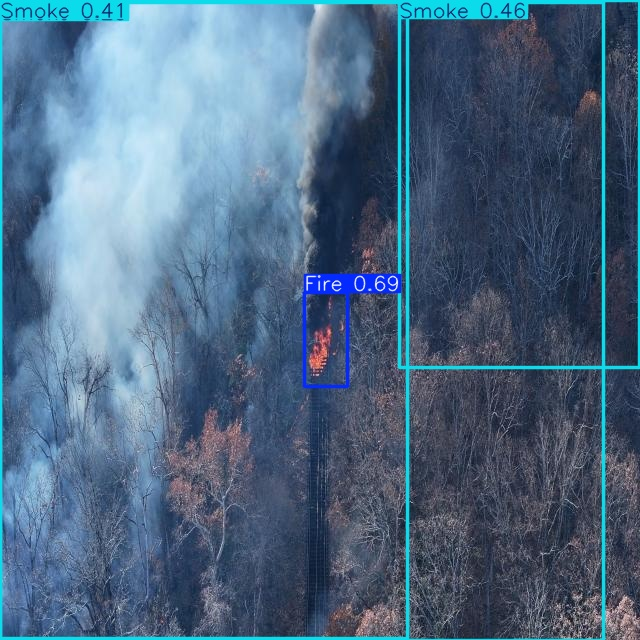

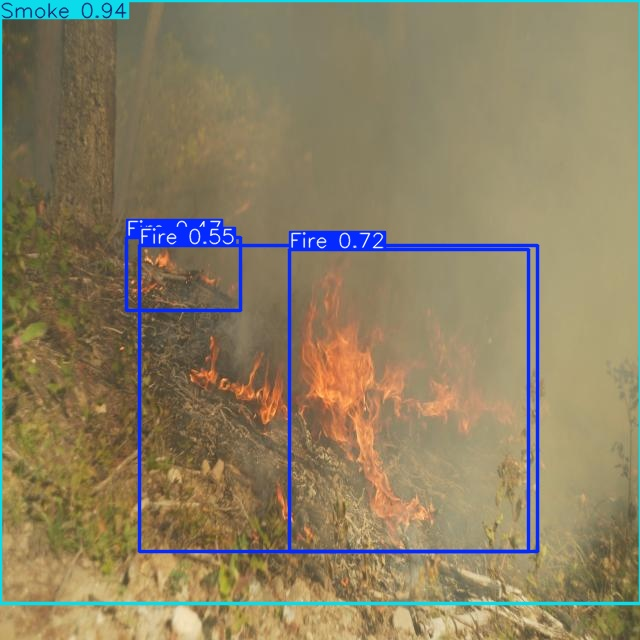

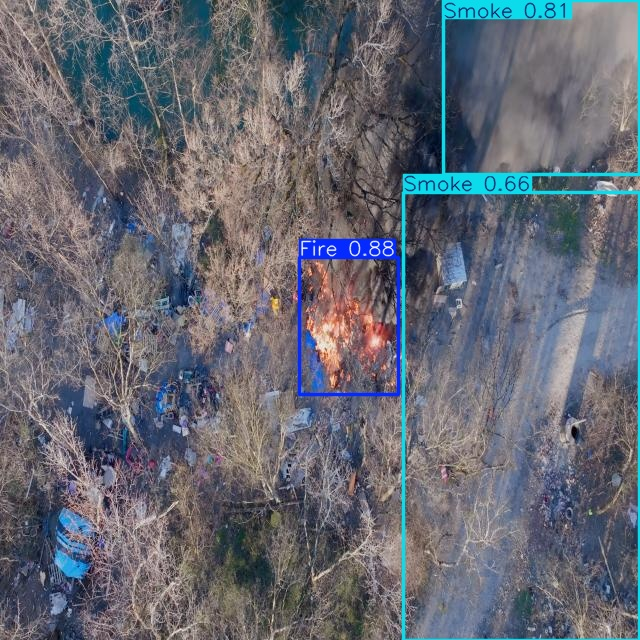

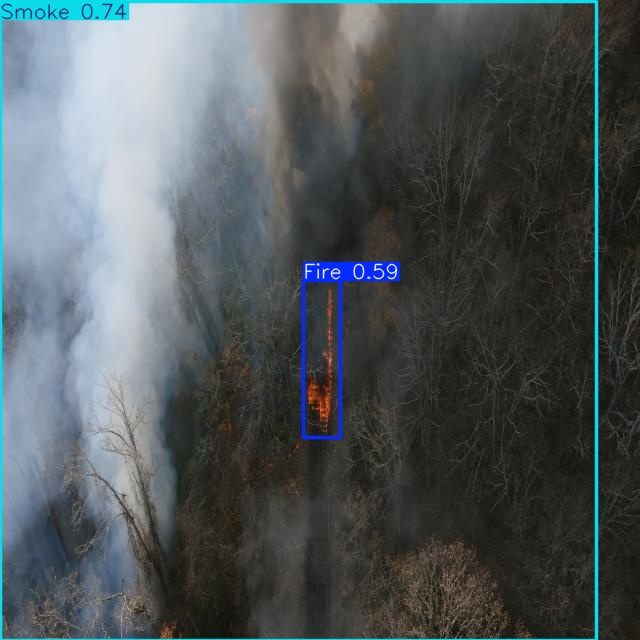

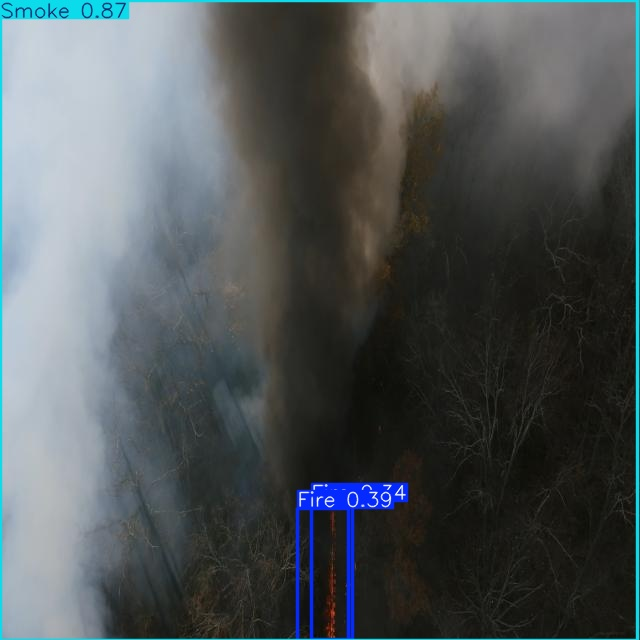

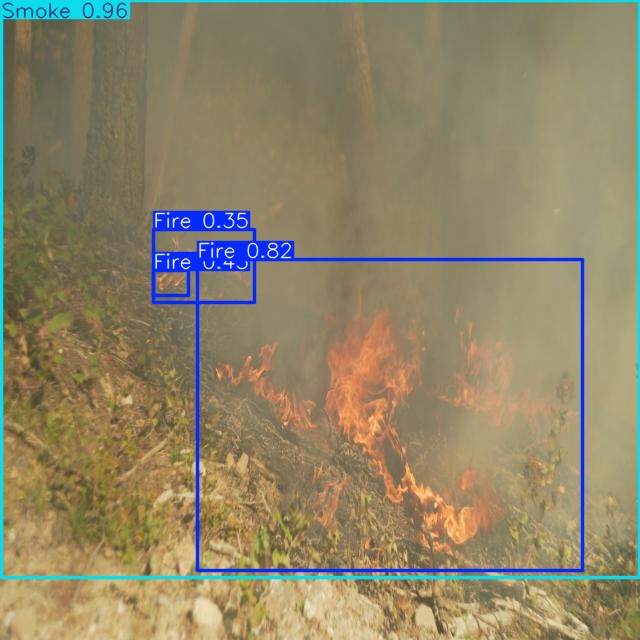

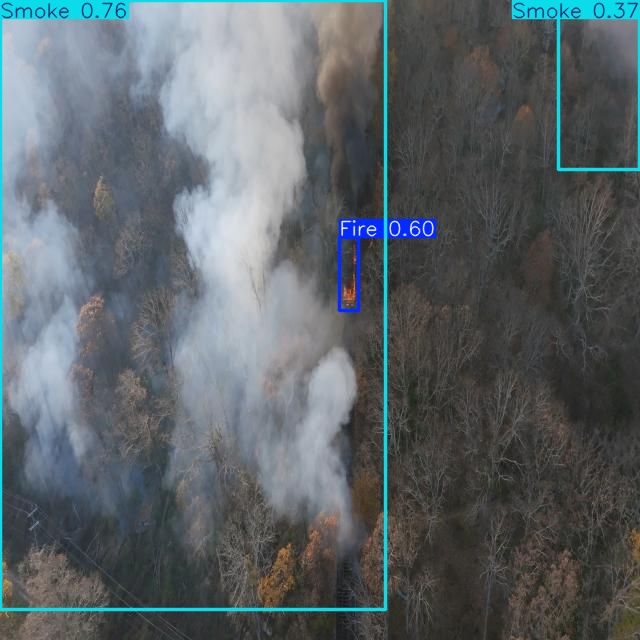

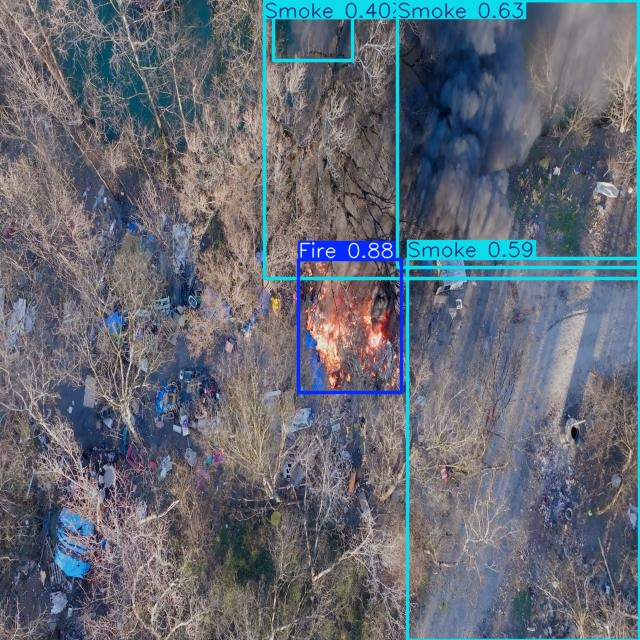

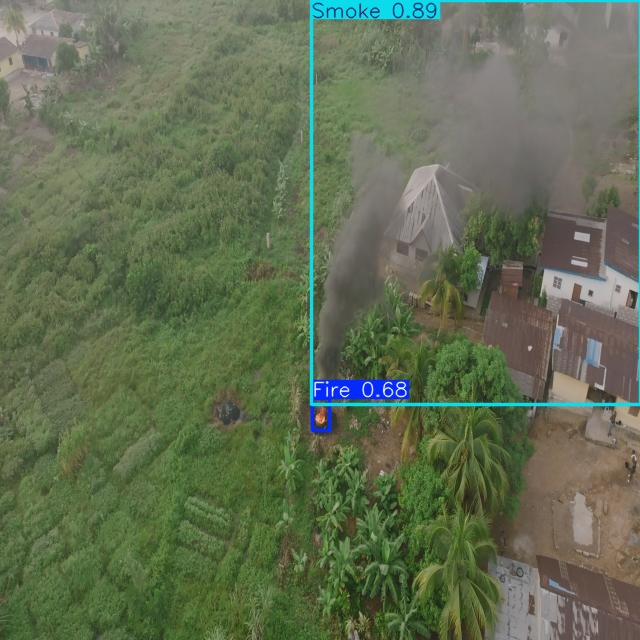

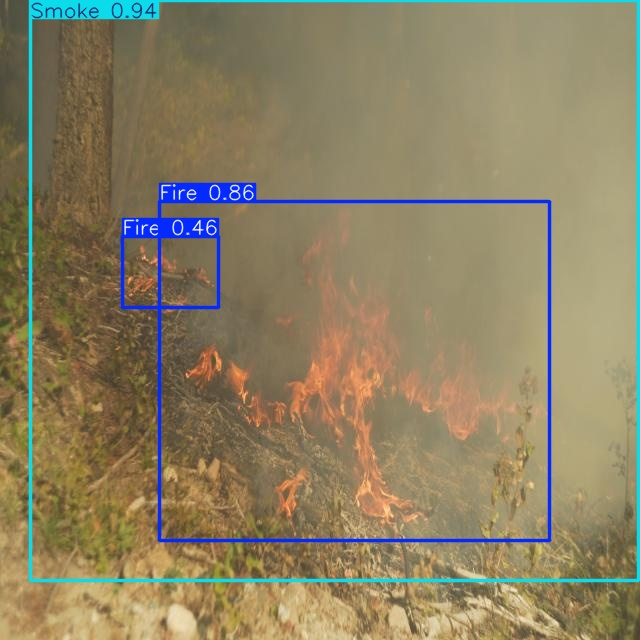

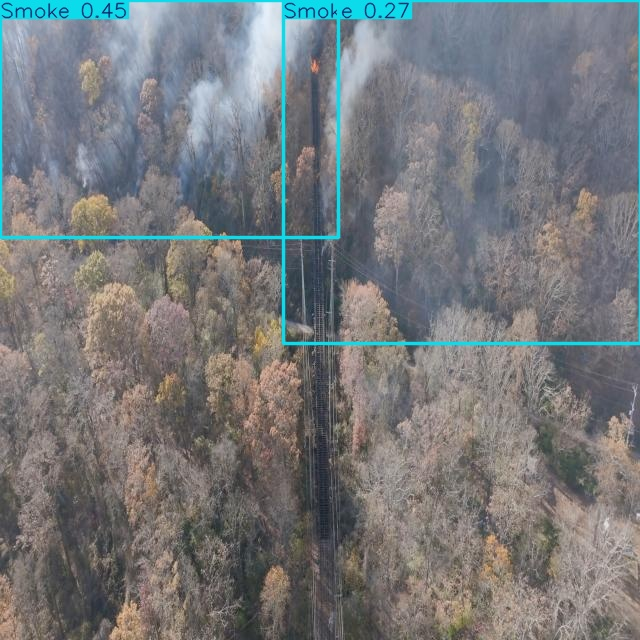

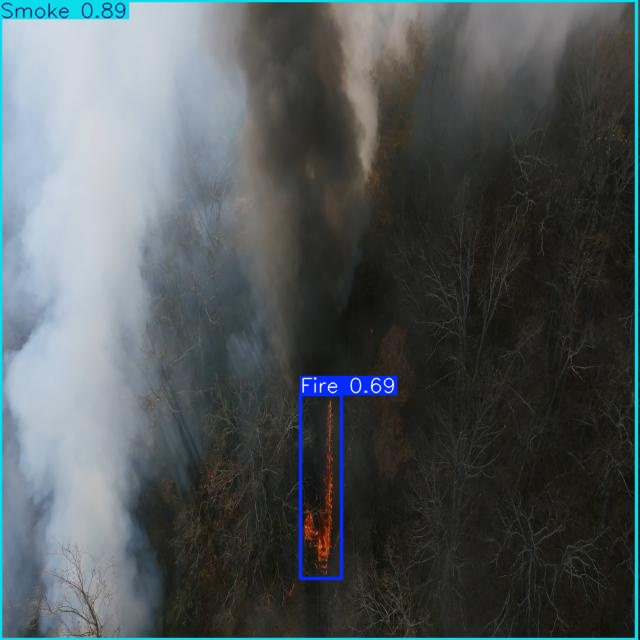

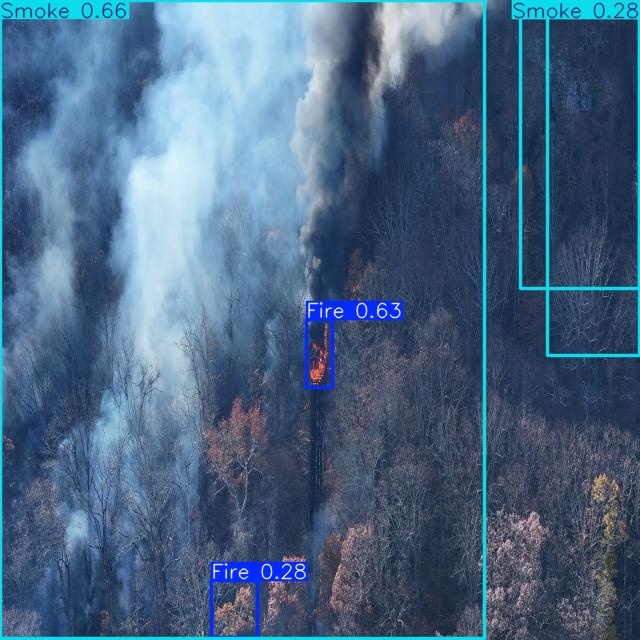

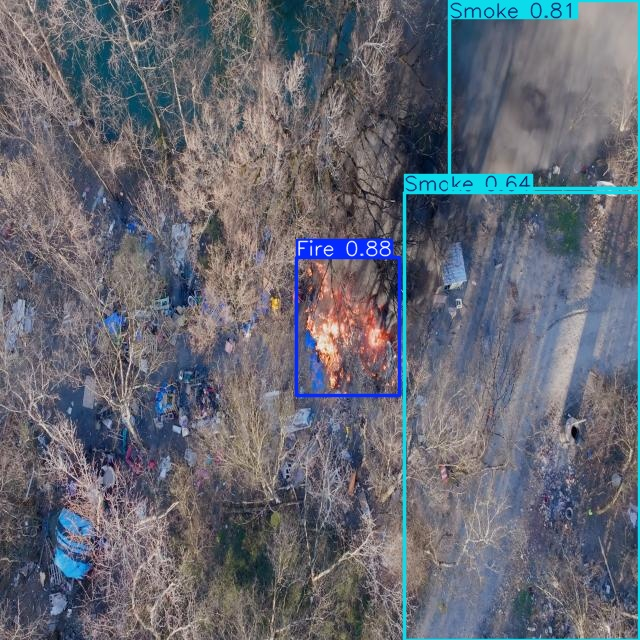

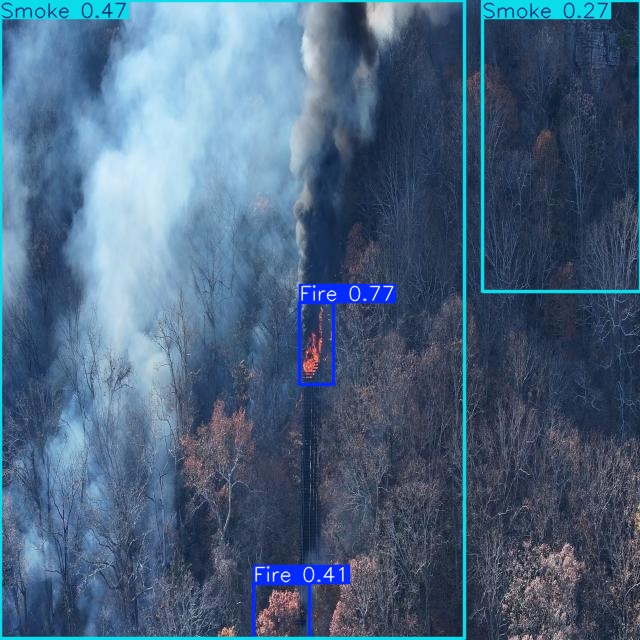

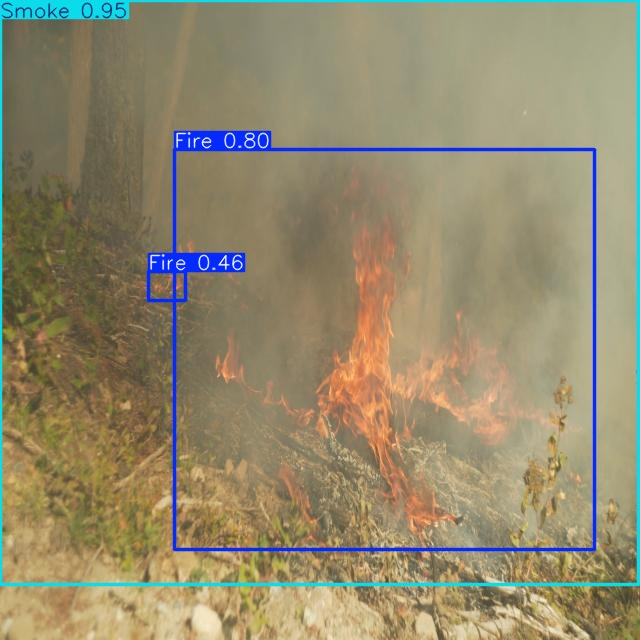

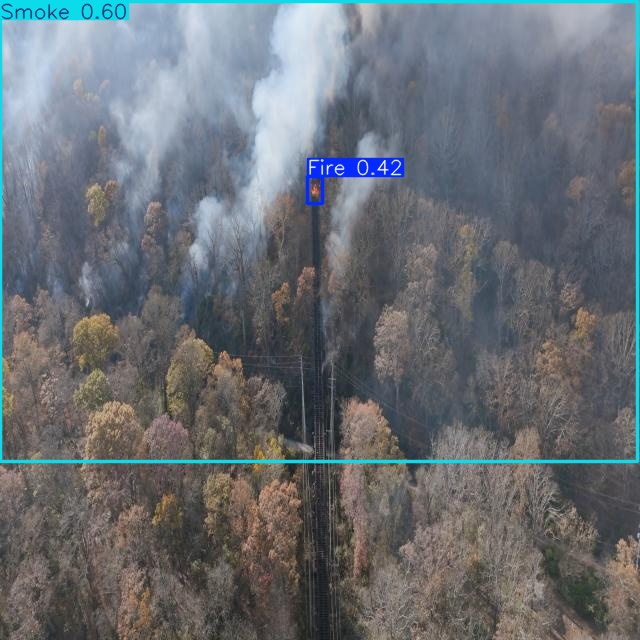

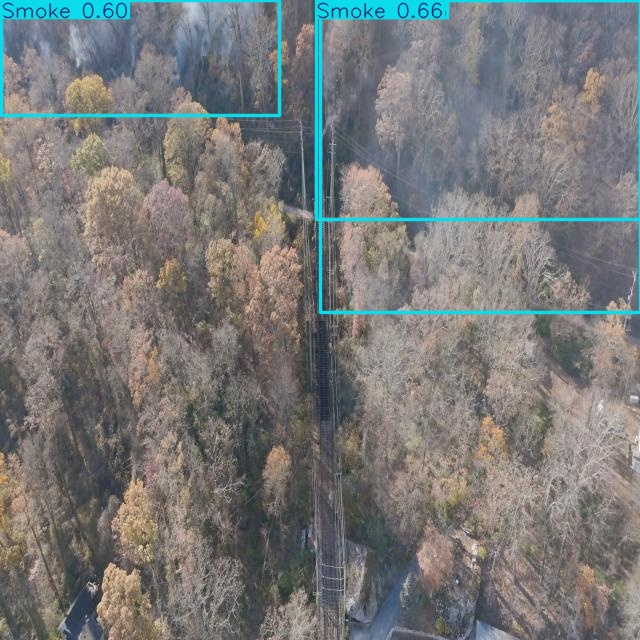

In [ ]:
from IPython.display import display, Image
import glob

for img in glob.glob("/content/runs/detect/predict/*.jpg"):
    display(Image(filename=img))

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving 204361-924209264.mp4 to 204361-924209264.mp4


In [ ]:
from ultralytics import YOLO

model = YOLO("/content/runs/detect/train/weights/best.pt")

In [ ]:
results = model.predict(
    source="/content/204361-924209264.mp4",
    conf=0.25,
    save=True,
    project="/content/video_test",
    name="result",
    exist_ok=True
)



WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/495) /content/204361-924209264.mp4: 384x640 1 Smoke, 8.8ms
video 1/1 (frame 2/495) /content/204361-924209264.mp4: 384x640 1 Smoke, 11.0ms
video 1/1 (frame 3/495) /content/204361-924209264.mp4: 384x640 1 Smoke, 10.3ms
video 1/1 (frame 4/495) /content/204361-924209264.mp4: 384x640 1 Smoke, 10.6ms
video 1/1 (frame 5/495) /content/204361-924209264.mp4: 384x640 1 Smoke, 11.0ms
video 1/1 (frame 6/495) /content/204361-924209264.mp4: 384x640 1 

In [ ]:
import os

folder = "/content/video_test/result"

print("Output files for 204361-924209264.mp4:")

if os.path.exists(folder):
    for file in os.listdir(folder):
        path = os.path.join(folder, file)
        print(file, "→", os.path.getsize(path), "bytes")
else:
    print("Output folder not found. Run video prediction first.")

Output files for 204361-924209264.mp4:
204361-924209264.avi → 202856480 bytes


In [ ]:
!ffmpeg -y -i "/content/video_test/result/204361-924209264.avi" \
-c:v libx264 -pix_fmt yuv420p -c:a aac -movflags +faststart \
"/content/video_test/result/fire_smoke_result.mp4"

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [ ]:
from IPython.display import Video

Video(
    "/content/video_test/result/fire_smoke_result.mp4",
    embed=True,
    width=800
)